# Неделя 10. Градиентные методы: адаптивный выбор шага

Скорость градиентного спуска $x_{k+1} = x_k - \alpha_k\nabla f(x_k)$ зависит от того, насколько шаг $\alpha_k$ согласован с
кривизной функции. Теоретический шаг $1/L$ требует знать глобальную константу Липшица градиента. Обычно она
неизвестна, а её оценки сильно завышены в той области, где метод реально работает. Разберём, как подбирать шаг по ходу
работы: какие условия на шаг разумны, почему они гарантируют сходимость, как выглядят геометрически и сколько стоят.

In [1]:
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams.update({
    "figure.figsize": (12, 5), "legend.fontsize": 11, "axes.labelsize": 13,
    "axes.titlesize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "lines.linewidth": 1.8,
})
np.set_printoptions(precision=4, suppress=True)

In [2]:
class Oracle:
    '''Обёртка над f и grad f со счётчиками вызовов.'''
    def __init__(self, f, gradf):
        self._f, self._g = f, gradf
        self.nf = self.ng = 0
    def f(self, x):
        self.nf += 1; return self._f(x)
    def gradf(self, x):
        self.ng += 1; return self._g(x)


class GradientDescent:
    def __init__(self, StepSizeChoice, name=None):
        self.name, self.StepSizeChoice = name, StepSizeChoice
        self.history = []                       # (x, время, вызовы f, вызовы grad, шаг)

    def solve(self, x0, f, gradf, tol=1e-6, max_iter=10000):
        oracle = Oracle(f, gradf)
        if hasattr(self.StepSizeChoice, "reset"):
            self.StepSizeChoice.reset()
        x = np.array(x0, dtype=float)
        t0 = time.time()
        self.history = [(x, 0.0, 0, 0, np.nan)]
        for k in range(max_iter):
            g = oracle.gradf(x)
            if np.linalg.norm(g) <= tol:
                break
            h = -g
            alpha = self.StepSizeChoice(x, h, k, oracle.gradf, oracle.f)
            x = x + alpha * h
            self.history.append((x, time.time() - t0, oracle.nf, oracle.ng, alpha))
        return x


def f_cached(rule, x, f):
    """f(x_k) уже посчитано правилом на прошлой итерации (в принятой пробной точке) — не пересчитываем."""
    c = getattr(rule, "cache", None)
    return c[1] if c is not None and np.array_equal(c[0], x) else f(x)


def slack(fx):
    """Допуск на ошибки округления: при ‖∇f‖ → 0 убывание c·α·‖∇f‖² становится меньше
    машинной точности относительно |f|, и без допуска проверка «f убыла» начинает ложно не проходить."""
    return 10 * np.finfo(float).eps * max(1.0, abs(fx))


XLABELS = {"iter": "Итерации, $k$", "time": "Время, с", "calls": r"Вызовы оракула ($f$ + $\nabla f$)"}

def plot_methods(methods, funcx, ylabel=r"$\|\nabla f(x_k)\|$", x_axis="iter", ax=None, title=None):
    if ax is None:
        _, ax = plt.subplots()
    for m in methods:
        xs = {"iter": lambda i, r: i, "time": lambda i, r: r[1], "calls": lambda i, r: r[2] + r[3]}[x_axis]
        ax.semilogy([xs(i, r) for i, r in enumerate(m.history)], [funcx(r[0]) for r in m.history], label=m.name)
    ax.set_xlabel(XLABELS[x_axis]); ax.set_ylabel(ylabel)
    if title: ax.set_title(title)
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
    return ax

def summary(methods):
    print(f"{'правило':30s} {'итераций':>9} {'вызовов f':>10} {'вызовов ∇f':>11} {'время, с':>9}")
    for m in methods:
        _, tt, nf, ng, _ = m.history[-1]
        print(f"{m.name:30s} {len(m.history)-1:9d} {nf:10d} {ng:11d} {tt:9.2f}")

## 1. Лемма о спуске и мотивация backtracking

**Утверждение 1 (лемма о спуске).** Пусть $\nabla f$ липшицев с константой $L$. Тогда для шага градиентного спуска
$x^+ = x - \alpha\nabla f(x)$
$$
f(x^+) \le f(x) - \alpha\Bigl(1 - \frac{\alpha L}{2}\Bigr)\|\nabla f(x)\|^2 .
$$


Из леммы следуют два факта:
* при любом $\alpha\in(0, 2/L)$ значение $f$ убывает, и лучшая гарантия $\frac1{2L}\|\nabla f\|^2$ достигается при $\alpha = 1/L$,
* при $\alpha\le 1/L$ выполнено $f(x^+)\le f(x) - \frac\alpha2\|\nabla f(x)\|^2$, то есть условие Армихо с параметром $c = \tfrac12$.

Второй факт означает, что проверяемое условие убывания выполнено для всех достаточно малых шагов, и порог $1/L$ знать
для этого не нужно. Можно начать с большого шага и дробить его, пока условие не выполнится.

**Утверждение 2 (backtracking: стоимость и сходимость).** Пусть $\nabla f$ $L$-липшицев. Правило: начинаем с $\alpha_0$ и
умножаем шаг на $\rho\in(0,1)$, пока не выполнено
$f(x - \alpha\nabla f(x)) \le f(x) - c\,\alpha\|\nabla f(x)\|^2$, $c\in(0, \tfrac12]$. Тогда
1. дробление заканчивается не более чем за $\bigl\lceil\log_{1/\rho}(\alpha_0L)\bigr\rceil_+$ шагов, и принятый шаг
   $\alpha_k\ge\alpha_{\min} := \min\{\alpha_0, \rho/L\}$,
2. для выпуклой $f$: $f(x_k) - f^*\le\dfrac{\|x_0 - x^*\|^2}{2\alpha_{\min}k}$, а для $\mu$-сильно выпуклой: $f(x_k) - f^*\le(1 - 2c\,\mu\alpha_{\min})^k\bigl(f(x_0) - f^*\bigr)$.


Backtracking даёт те же порядки скорости, что и шаг $1/L$, с потерей постоянного множителя $\rho$, и не требует знать $L$.
Платим за это дополнительными вычислениями $f$, не больше $\log_{1/\rho}(\alpha_0L)$ на итерацию.

### 1.1. Проверка на задаче

Данные: кусочно-линейный сигнал $x_{\rm true}$ из $n = 1000$ отсчётов, измеренный с шумом: $y = x_{\rm true} + \xi$, $\xi\sim\mathcal N(0, 0.35^2I)$.

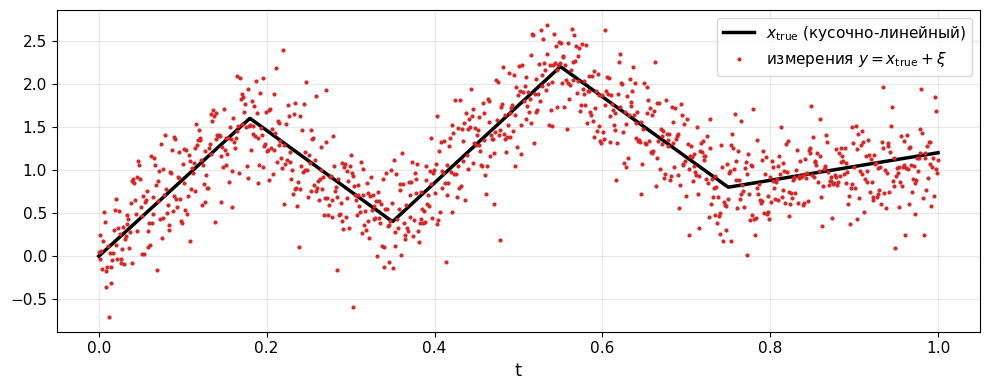

In [3]:
rng_demo = np.random.default_rng(0)
t_demo = np.linspace(0, 1, 1000)
x_true_demo = np.interp(t_demo, [0, .18, .35, .55, .75, 1.], [0., 1.6, .4, 2.2, .8, 1.2])
y_demo = x_true_demo + 0.35 * rng_demo.standard_normal(1000)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_demo, x_true_demo, "k-", lw=2.5, label=r"$x_{\rm true}$ (кусочно-линейный)")
ax.plot(t_demo, y_demo, ".", color="C3", ms=4, label=r"измерения $y = x_{\rm true} + \xi$")
ax.set_xlabel("t"); ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

Хотим восстановить сигнал по $y$. У кусочно-линейного сигнала вторая разность $(Dx)_i = x_{i+1} - 2x_i + x_{i-1}$ почти всюду
равна нулю, поэтому штрафуем её сглаженным модулем (аналог полной вариации производной):
$$
f(x) = \|x - y\|_2^2 + \lambda\sum_i\sqrt{(Dx)_i^2 + \varepsilon},\qquad
\nabla f(x) = 2(x - y) + \lambda D^\top\Bigl(\frac{Dx}{\sqrt{(Dx)^2 + \varepsilon}}\Bigr).
$$
Задача $2$-сильно выпукла, $L\le2 + \lambda\|D\|^2/\sqrt\varepsilon$.

In [4]:
def second_diff(n):
    D = np.zeros((n - 2, n))
    for i in range(n - 2):
        D[i, i], D[i, i + 1], D[i, i + 2] = 1.0, -2.0, 1.0
    return D


def make_signal_problem(n=1000, lam=0.3, eps=1e-5, noise=0.35, seed=0):
    rng = np.random.default_rng(seed)
    t = np.linspace(0, 1, n)
    x_true = np.interp(t, [0, .18, .35, .55, .75, 1.], [0., 1.6, .4, 2.2, .8, 1.2])
    y = x_true + noise * rng.standard_normal(n)
    D = second_diff(n)

    def f(x):
        r = x - y; d = D @ x
        return r @ r + lam * np.sum(np.sqrt(d * d + eps))

    def gradf(x):
        d = D @ x
        return 2 * (x - y) + lam * (D.T @ (d / np.sqrt(d * d + eps)))

    L = 2 + lam * np.linalg.norm(D, 2) ** 2 / np.sqrt(eps)
    return dict(f=f, gradf=gradf, L=L, x0=y.copy(), t=t, x_true=x_true, y=y, D=D, lam=lam, eps=eps)


P = make_signal_problem()
f, gradf, L, x0 = P["f"], P["gradf"], P["L"], P["x0"]
print(f"n = {len(x0)},  mu = 2,  L <= {L:.0f},  kappa <= {L/2:.0f}")

n = 1000,  mu = 2,  L <= 1520,  kappa <= 760


Проверим оценку числа дроблений из утверждения 2: при $\alpha_0 = 1$ и $\rho = \tfrac12$ дроблений на итерацию должно быть
не больше $\lceil\log_2 L\rceil$.

In [5]:
class Backtracking:
    '''Армихо с дроблением; warm=True: стартуем с удвоенного предыдущего шага.'''
    def __init__(self, c=0.5, rho=0.5, alpha0=1.0, warm=False):
        self.c, self.rho, self.alpha0, self.warm = c, rho, alpha0, warm
        self.reset()
    def reset(self):
        self.prev = None; self.n_back = []; self.cache = None
    def __call__(self, x, h, k, gradf, f):
        alpha = self.alpha0 if (not self.warm or self.prev is None) else 2 * self.prev
        fx, hg = f_cached(self, x, f), -(h @ h)    # <grad f(x), h> при h = -grad f(x)
        nb = 0
        while (fa := f(x + alpha * h)) > fx + self.c * alpha * hg + slack(fx):
            alpha *= self.rho; nb += 1
        self.prev = alpha; self.n_back.append(nb); self.cache = (x + alpha * h, fa)
        return alpha

bt = Backtracking(c=0.5)
m_bt = GradientDescent(bt, name="backtracking")
m_bt.solve(x0, f, gradf, tol=1e-4, max_iter=60000)
steps = np.array([r[4] for r in m_bt.history[1:]])
print(f"итераций: {len(steps)}")
print(f"дроблений на итерацию: max = {max(bt.n_back)}, среднее = {np.mean(bt.n_back):.1f};  "
      f"оценка ⌈log2 L⌉ = {int(np.ceil(np.log2(L)))}")
print(f"принятый шаг: min = {steps.min():.2e}, медиана = {np.median(steps):.2e};  "
      f"гарантия rho/L = {0.5 / L:.2e},  1/L = {1 / L:.2e}")

итераций: 1173
дроблений на итерацию: max = 11, среднее = 8.8;  оценка ⌈log2 L⌉ = 11
принятый шаг: min = 4.88e-04, медиана = 1.95e-03;  гарантия rho/L = 3.29e-04,  1/L = 6.58e-04


Оценка выполняется: дроблений не больше $\lceil\log_2L\rceil$, и принятый шаг не меньше $\rho/L$. Медианный шаг при этом
втрое больше $1/L$, потому что кривизна вдоль траектории меньше априорной оценки $L$. На этом запасе и выигрывают
адаптивные правила.

## 2. Условия на шаг: Армихо, Вольф, Гольдштейн

Пусть $d$ направление убывания: $\langle\nabla f(x), d\rangle < 0$. Обозначим $\varphi(\alpha) = f(x + \alpha d)$, тогда $\varphi'(0) =
\langle\nabla f(x), d\rangle < 0$.

**Утверждение 3 (условие Армихо).** Условие достаточного убывания
$$\varphi(\alpha)\le\varphi(0) + c_1\alpha\varphi'(0),\qquad c_1\in(0,1),$$
выполнено для всех $\alpha\in(0, \bar\alpha]$ при некотором $\bar\alpha > 0$.


Условие Армихо допускает сколь угодно малые шаги. Прогресс оно гарантирует только вместе с правилом, которое
начинает с большого шага (backtracking) или явно запрещает малые шаги.

**Утверждение 4 (условия Вольфа).** Пусть $0 < c_1 < c_2 < 1$, $f\in C^1$ и $\varphi$ ограничена снизу при $\alpha > 0$. Тогда
существует интервал шагов, на котором одновременно выполнены
$$
\text{(W1)}\ \ \varphi(\alpha)\le\varphi(0) + c_1\alpha\varphi'(0),
\qquad
\text{(W2)}\ \ \varphi'(\alpha)\ge c_2\varphi'(0),
$$
и даже сильное условие (W2$'$) $|\varphi'(\alpha)|\le c_2|\varphi'(0)|$. Если вдобавок $\nabla f$ $L$-липшицев, то любой шаг с (W2)
отделён от нуля: $\alpha\ge\dfrac{(1 - c_2)|\varphi'(0)|}{L\|d\|^2}$.


**Утверждение 5 (условия Гольдштейна).** Пусть $c\in(0, \tfrac12)$ и $\varphi$ ограничена снизу. Тогда существует интервал шагов с
$$\varphi(0) + (1 - c)\alpha\varphi'(0)\ \le\ \varphi(\alpha)\ \le\ \varphi(0) + c\,\alpha\varphi'(0).$$
Для квадратичной $\varphi$ её минимум $\alpha^*$ всегда удовлетворяет этим условиям, поэтому и берут $c < \tfrac12$.


Нижнее условие Гольдштейна может отрезать минимум $\varphi$, если $\varphi$ далека от квадратичной. Поэтому в
квазиньютоновских методах и сопряжённых градиентах используют условия Вольфа, а Гольдштейна в основном в методах
ньютоновского типа, где хороший шаг равен $1$.

**Утверждение 6.** Пусть $f$ ограничена снизу, $\nabla f$ $L$-липшицев, шаги удовлетворяют условиям Вольфа, а
направления удовлетворяют $\cos\theta_k = \frac{-\langle\nabla f(x_k), d_k\rangle}{\|\nabla f(x_k)\|\|d_k\|}\ge\delta > 0$. Тогда $\sum_k\cos^2\theta_k\|\nabla f(x_k)\|^2 < \infty$ и, значит,
$\|\nabla f(x_k)\|\to0$.


## 3. Геометрический смысл условий

Все условия записываются через одну функцию $\varphi(\alpha) = f(x + \alpha d)$ и прямые через точку $(0, \varphi(0))$.
* Армихо (W1): график $\varphi$ лежит ниже прямой с наклоном $c_1\varphi'(0)$, более пологой, чем касательная. Запрещены
  слишком большие шаги, на которых функция убыла мало или выросла.
* Условие кривизны (W2): наклон $\varphi'(\alpha)$ не круче $c_2\varphi'(0)$. Запрещены слишком малые шаги, где $\varphi$ ещё круто
  убывает и выгоднее идти дальше.
* Сильное условие (W2$'$): $|\varphi'(\alpha)|$ мал, то есть шаг лежит рядом со стационарной точкой $\varphi$. Запрещены и шаги,
  где $\varphi$ уже круто растёт.
* Гольдштейн: график $\varphi$ зажат между двумя прямыми с наклонами $c\varphi'(0)$ и $(1 - c)\varphi'(0)$. Малые шаги отрезает
  нижняя прямая, и производные не нужны.

Нарисуем допустимые множества на срезе функции Розенброка: $\varphi(\alpha) = f(x + \alpha d)$ из точки $(-1.2,\ 1)$ по антиградиенту.

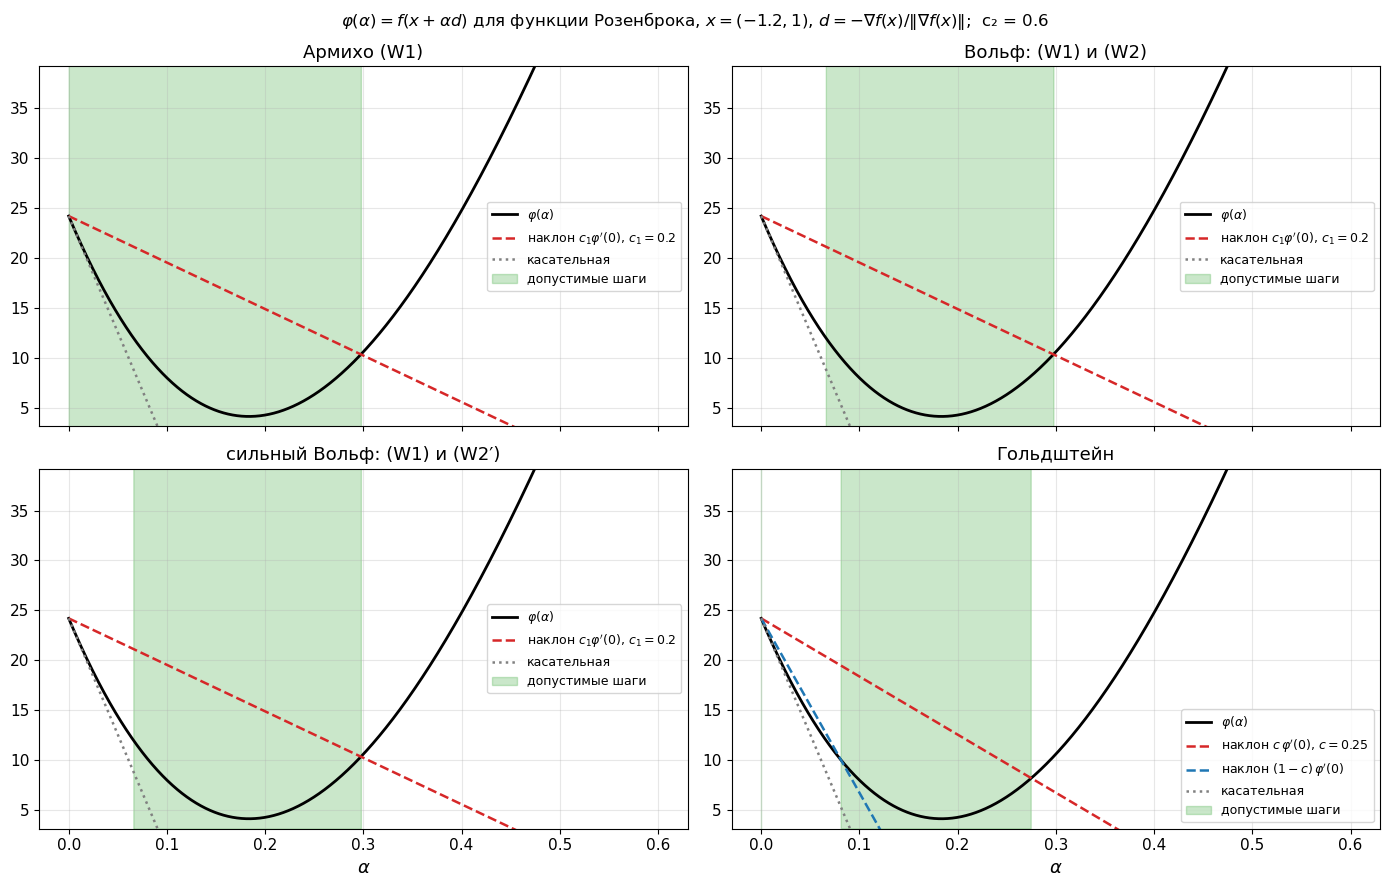

Армихо (W1)                   : [0.000, 0.297]
Вольф: (W1) и (W2)            : [0.066, 0.297]
сильный Вольф: (W1) и (W2′)   : [0.066, 0.297]
Гольдштейн                    : [0.000, 0.000], [0.081, 0.275]
минимум φ на отрезке: α* = 0.183


In [6]:
rosen   = lambda x: 100 * (x[1] - x[0]**2)**2 + (x[0] - 1)**2
rosen_g = lambda x: np.array([-400 * x[0] * (x[1] - x[0]**2) + 2 * (x[0] - 1), 200 * (x[1] - x[0]**2)])

xg = np.array([-1.2, 1.0]); dg = -rosen_g(xg); dg = dg / np.linalg.norm(dg)
phi  = lambda a: rosen(xg + a * dg)
dphi = lambda a: rosen_g(xg + a * dg) @ dg
al = np.linspace(0, 0.6, 3000)
ph = np.array([phi(a) for a in al]); dph = np.array([dphi(a) for a in al])
p0, d0 = phi(0), dphi(0)
c1, c2, cg = 0.2, 0.6, 0.25

conds = {
    "Армихо (W1)":                   ph <= p0 + c1 * al * d0,
    "Вольф: (W1) и (W2)":            (ph <= p0 + c1 * al * d0) & (dph >= c2 * d0),
    "сильный Вольф: (W1) и (W2′)":   (ph <= p0 + c1 * al * d0) & (np.abs(dph) <= c2 * abs(d0)),
    "Гольдштейн":                    (ph <= p0 + cg * al * d0) & (ph >= p0 + (1 - cg) * al * d0),
}
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, (name, ok) in zip(axes.ravel(), conds.items()):
    ax.plot(al, ph, "k", lw=2, label=r"$\varphi(\alpha)$")
    if "Гольдштейн" in name:
        ax.plot(al, p0 + cg * al * d0, "C3--", label=fr"наклон $c\,\varphi'(0)$, $c={cg}$")
        ax.plot(al, p0 + (1 - cg) * al * d0, "C0--", label=r"наклон $(1-c)\,\varphi'(0)$")
    else:
        ax.plot(al, p0 + c1 * al * d0, "C3--", label=fr"наклон $c_1\varphi'(0)$, $c_1={c1}$")
    ax.plot(al, p0 + al * d0, ":", color="gray", label="касательная")
    lo, hi = ph.min() - 1, ph.max() + 1
    ax.fill_between(al, lo, hi, where=ok, color="C2", alpha=0.25, label="допустимые шаги")
    ax.set_ylim(lo, min(hi, p0 + 15)); ax.set_title(name); ax.grid(alpha=0.3); ax.legend(fontsize=9)
for ax in axes[1]: ax.set_xlabel(r"$\alpha$")
plt.suptitle(r"$\varphi(\alpha) = f(x+\alpha d)$ для функции Розенброка, $x = (-1.2, 1)$, $d = -\nabla f(x)/\|\nabla f(x)\|$" + f";  c₂ = {c2}")
plt.tight_layout(); plt.show()

a_star = al[np.argmin(ph)]
for name, ok in conds.items():
    segs = np.flatnonzero(np.diff(np.r_[0, ok.astype(int), 0]))
    iv = ", ".join(f"[{al[s]:.3f}, {al[min(e, len(al)) - 1]:.3f}]" for s, e in zip(segs[::2], segs[1::2]))
    print(f"{name:30s}: {iv}")
print(f"минимум φ на отрезке: α* = {a_star:.3f}")

Каждое следующее условие сужает множество. Армихо разрешает все шаги от нуля до точки, где $\varphi$ пересекает прямую
$c_1\varphi'(0)$, включая бесполезно малые. Условие кривизны (W2) отрезает начальный участок, где $\varphi$ ещё круто падает.
Сильное условие оставляет только окрестности стационарных точек $\varphi$. Гольдштейн отрезает малые шаги нижней прямой,
а вместе с ними может отрезать и часть окрестности минимума $\varphi$.

## 4. Реализация правил и сравнение

Все правила выбора шага реализованы как функторы `(x, h, k, gradf, f) -> alpha`:
* постоянный шаг $1/L$,
* точный одномерный поиск (бисекция по знаку $\varphi'$: для выпуклой $f$ производная $\varphi'$ возрастает),
* backtracking по Армихо с $\alpha_0 = 1$ и с тёплым стартом $\alpha_0 = 2\alpha_{k-1}$,
* поиск по условиям Вольфа и Гольдштейна (бисекция по отрезку $[\text{lb}, \text{ub}]$).

In [7]:
class ConstantStepSize:
    def __init__(self, alpha): self.alpha = alpha
    def __call__(self, x, h, k, *a, **kw): return self.alpha


class ExactLineSearch:
    '''Бисекция по phi'(a) = <grad f(x + a h), h>.'''
    def __init__(self, a0=1.0, tol=1e-10, max_iter=50, a_max=1e12):
        self.a0, self.tol, self.max_iter, self.a_max = a0, tol, max_iter, a_max
    def __call__(self, x, h, k, gradf, f):
        dphi = lambda a: gradf(x + a * h) @ h
        hi = self.a0
        while dphi(hi) < 0 and hi < self.a_max:
            hi *= 2.0
        lo = 0.0
        for _ in range(self.max_iter):
            mid = 0.5 * (lo + hi)
            if dphi(mid) < 0: lo = mid
            else: hi = mid
            if hi - lo <= self.tol * max(1.0, hi): break
        return 0.5 * (lo + hi)


class WolfeSearch:
    '''Бисекция: (W1) нарушено -> уменьшаем, (W2) нарушено -> увеличиваем.'''
    def __init__(self, c1=1e-4, c2=0.9, alpha0=1.0, max_it=60, warm=False):
        self.c1, self.c2, self.a0, self.max_it, self.warm = c1, c2, alpha0, max_it, warm
        self.prev = None; self.cache = None
    def reset(self): self.prev = None; self.cache = None
    def __call__(self, x, h, k, gradf, f):
        lb, ub = 0.0, np.inf
        a = self.a0 if (not self.warm or self.prev is None) else 2 * self.prev
        fx = f_cached(self, x, f); d0 = -(h @ h)          # ∇f(x) уже известен: h = −∇f(x)
        for _ in range(self.max_it):
            fa = f(x + a * h)
            if fa > fx + self.c1 * a * d0 + slack(fx):
                ub = a; a = 0.5 * (lb + ub)
            elif gradf(x + a * h) @ h < self.c2 * d0:
                lb = a; a = 2 * lb if np.isinf(ub) else 0.5 * (lb + ub)
            else:
                break
        self.prev = a; self.cache = (x + a * h, fa)
        return a


class GoldsteinSearch:
    '''Бисекция между двумя прямыми; производные не нужны.'''
    def __init__(self, c=0.25, alpha0=1.0, max_it=60, warm=False):
        self.c, self.a0, self.max_it, self.warm = c, alpha0, max_it, warm
        self.prev = None; self.cache = None
    def reset(self): self.prev = None; self.cache = None
    def __call__(self, x, h, k, gradf, f):
        lb, ub = 0.0, np.inf
        a = self.a0 if (not self.warm or self.prev is None) else 2 * self.prev
        fx = f_cached(self, x, f); d0 = -(h @ h)
        for _ in range(self.max_it):
            fa = f(x + a * h)
            if fa > fx + self.c * a * d0 + slack(fx):
                ub = a; a = 0.5 * (lb + ub)
            elif fa < fx + (1 - self.c) * a * d0 - slack(fx):
                lb = a; a = 2 * lb if np.isinf(ub) else 0.5 * (lb + ub)
            else:
                break
        self.prev = a; self.cache = (x + a * h, fa)
        return a

правило                         итераций  вызовов f  вызовов ∇f  время, с
GD, 1/L                             8547          0        8547     11.76
точный поиск                        3094          0      111384    148.59
Армихо, α₀ = 1                      1703      16709        1703     15.35
Армихо, α₀ = 2α_{k−1}               2249       4508        2249      6.38
Вольф, α₀ = 1                       1703      16709        3406     16.40
Вольф, α₀ = 2α_{k−1}                2249       4508        4498     10.07
Гольдштейн, α₀ = 2α_{k−1}           1403       4244        1403      5.22


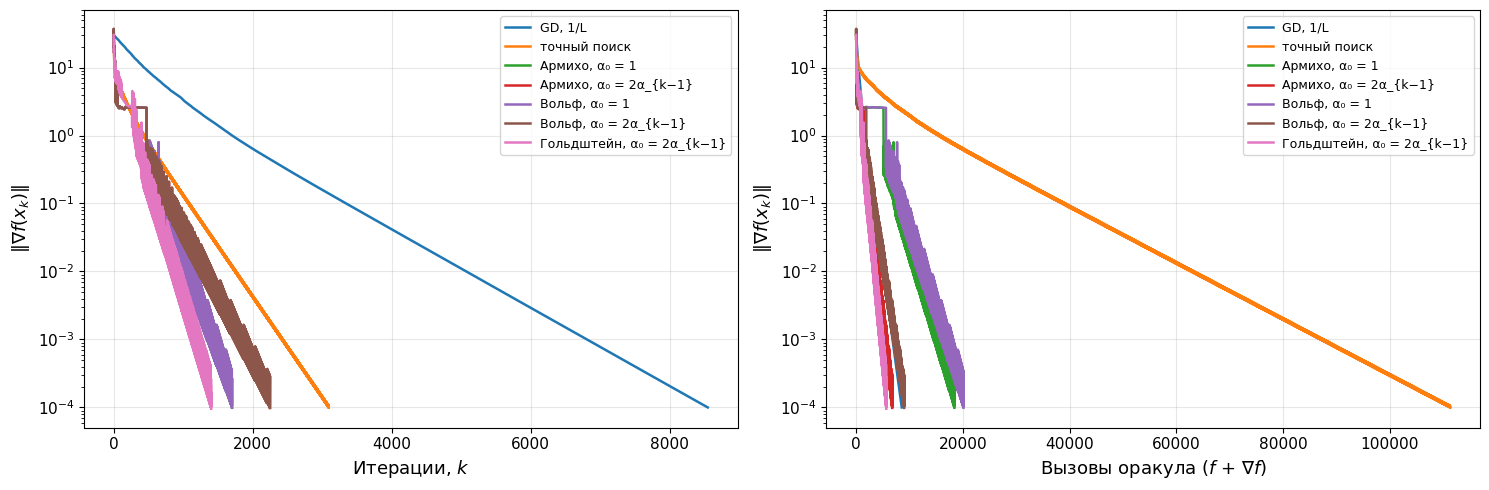

In [8]:
methods = [
    GradientDescent(ConstantStepSize(1 / L),        name="GD, 1/L"),
    GradientDescent(ExactLineSearch(),              name="точный поиск"),
    GradientDescent(Backtracking(c=1e-4),           name="Армихо, α₀ = 1"),
    GradientDescent(Backtracking(c=1e-4, warm=True), name="Армихо, α₀ = 2α_{k−1}"),
    GradientDescent(WolfeSearch(),                  name="Вольф, α₀ = 1"),
    GradientDescent(WolfeSearch(warm=True),         name="Вольф, α₀ = 2α_{k−1}"),
    GradientDescent(GoldsteinSearch(warm=True),     name="Гольдштейн, α₀ = 2α_{k−1}"),
]
for m in methods:
    m.solve(x0, f, gradf, tol=1e-4, max_iter=60000)
summary(methods)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
gn = lambda x: np.linalg.norm(gradf(x))
plot_methods(methods, gn, x_axis="iter", ax=axes[0])
plot_methods(methods, gn, x_axis="calls", ax=axes[1])
plt.tight_layout(); plt.show()

Все правила с подбором шага обходят постоянный шаг $1/L$ (8547 итераций): Армихо и Вольф в 4–5 раз по итерациям,
Гольдштейн в 6 раз (1415). Априорная $L$ завышена, и подобранные шаги в несколько раз больше $1/L$. Точный поиск
по итерациям почти не выигрывает у неточных правил (3094) и при этом очень дорог. Точно минимизирующий шаг
возвращает метод в зигзаг поперёк оврага, а неточный шаг Гольдштейна этот зигзаг ломает.

### 4.1. Чего стоит итерация

In [9]:
print(f"{'правило':30s} {'вызовов f на итерацию':>22} {'вызовов ∇f на итерацию':>23}")
for m in methods:
    k = len(m.history) - 1; _, _, nf, ng, _ = m.history[-1]
    print(f"{m.name:30s} {nf / k:22.2f} {ng / k:23.2f}")

правило                         вызовов f на итерацию  вызовов ∇f на итерацию
GD, 1/L                                          0.00                    1.00
точный поиск                                     0.00                   36.00
Армихо, α₀ = 1                                   9.81                    1.00
Армихо, α₀ = 2α_{k−1}                            2.00                    1.00
Вольф, α₀ = 1                                    9.81                    2.00
Вольф, α₀ = 2α_{k−1}                             2.00                    2.00
Гольдштейн, α₀ = 2α_{k−1}                        3.02                    1.00


Стоимость итерации у правил различается на порядок. Точный поиск тратит 36 градиентов на итерацию. Backtracking с
$\alpha_0 = 1$ тратит 10 вычислений $f$, столько раз приходится делить единицу пополам. С тёплым стартом вычислений два:
попытка с удвоенным шагом и одно дробление, а $f(x_k)$ берётся с прошлой итерации. По полному числу вызовов оракула
тёплый Армихо ($\approx6800$) лишь немного лучше шага $1/L$, а Гольдштейн ($\approx5700$) лучше в 1.5 раза. Условие на шаг
влияет в основном на число итераций, а начальный шаг на стоимость итерации, поэтому тёплый старт почти всегда стоит включать.

## 5. Адаптивные правила

Backtracking с $\alpha_0 = 1$ на каждой итерации заново спускается от единицы до нужного масштаба. Естественно запоминать
масштаб с прошлой итерации.

**Утверждение 7 (адаптивная оценка $L$).** Правило: положим $L_k := L_{k-1}/2$ и, пока
$f\bigl(x_k - \tfrac1{L_k}\nabla f(x_k)\bigr) > f(x_k) - \tfrac1{2L_k}\|\nabla f(x_k)\|^2$, удваиваем $L_k$. Шаг $\alpha_k = 1/L_k$. Если $\nabla f$
$L$-липшицев, то $L_k\le2L$ для всех $k$, а суммарное число пробных вычислений $f\bigl(x_k - \tfrac1{L_k}\nabla f(x_k)\bigr)$
за $N$ итераций не превосходит $2N + \log_2\frac{2L}{L_0}$. Значение $f(x_k)$ отдельно считать не нужно: это последняя
принятая пробная точка предыдущей итерации.


В среднем адаптивная оценка тратит около двух вычислений $f$ на итерацию, и шаг каждый раз близок к максимально
допустимому для текущей локальной кривизны. Это то же самое, что Армихо с $c = \tfrac12$ и тёплым стартом $\alpha_0 = 2\alpha_{k-1}$.

Можно вообще не вычислять $f$ и оценивать кривизну по двум последним градиентам, которые уже посчитаны:
* Барзилай–Борвейн: $\alpha_k = \dfrac{\|s_k\|^2}{\langle s_k, y_k\rangle}$, где $s_k = x_k - x_{k-1}$, $y_k = \nabla f(x_k) - \nabla f(x_{k-1})$. Это обратная кривизна
  вдоль последнего шага (подробнее в ДЗ №3). Метод немонотонен.
* AdGD (Малицкий, Мищенко, *Adaptive Gradient Descent without Descent*, ICML 2020):
  $L_k = \frac{\|y_k\|}{\|s_k\|}$, $\lambda_k = \min\bigl\{\sqrt{1 + \theta_{k-1}}\,\lambda_{k-1},\ \frac1{2L_k}\bigr\}$, $\theta_k = \lambda_k/\lambda_{k-1}$. Сходимость доказана
  для выпуклых функций.

In [10]:
class AdaptiveL:
    '''Утверждение 7: L_k = L_{k-1}/2, затем удваиваем до выполнения условия убывания.'''
    def __init__(self, L0=1.0): self.L0 = L0; self.reset()
    def reset(self): self.Lk = self.L0; self.L_hist = []; self.trials = 0; self.cache = None
    def __call__(self, x, h, k, gradf, f):
        self.Lk /= 2
        # f(x_k) берём из кэша: это принятая пробная точка прошлой итерации
        fx = self.cache[1] if self.cache is not None and np.array_equal(self.cache[0], x) else f(x)
        gg = h @ h
        while True:
            xn = x + (1 / self.Lk) * h; fn = f(xn); self.trials += 1   # ровно та точка, которую сделает GD
            if fn <= fx - gg / (2 * self.Lk) + slack(fx): break
            self.Lk *= 2
        self.cache = (xn, fn)
        self.L_hist.append(self.Lk)
        return 1 / self.Lk


class BB:
    def __init__(self, a0=1e-3): self.a0 = a0; self.reset()
    def reset(self): self.xp = self.gp = None
    def __call__(self, x, h, k, *a, **kw):
        g = -h
        if self.xp is None:
            alpha = self.a0
        else:
            s, y = x - self.xp, g - self.gp
            alpha = (s @ s) / (s @ y) if s @ y > 0 else self.a0
        self.xp, self.gp = x, g
        return alpha


class AdGD:
    '''Adaptive GD (Малицкий, Мищенко, 2020): f не вызывается вообще.'''
    def __init__(self, lam0=1e-10): self.lam0 = lam0; self.reset()
    def reset(self):
        self.x_prev = self.g_prev = None; self.lam_prev, self.theta = None, np.inf; self.L_hist = []
    def __call__(self, x, h, k, *a, **kw):
        g = -h
        if self.x_prev is None:
            lam = self.lam0
        else:
            dx = np.linalg.norm(x - self.x_prev); dg = np.linalg.norm(g - self.g_prev)
            Lk = dg / dx if dx > 0 else 0.0
            self.L_hist.append(Lk)
            lam = min(np.sqrt(1 + self.theta) * self.lam_prev, 1 / (2 * Lk) if Lk > 0 else np.inf)
            if np.isinf(lam): lam = self.lam_prev
            self.theta = lam / self.lam_prev
        self.x_prev, self.g_prev, self.lam_prev = x, g, lam
        return lam

правило                         итераций  вызовов f  вызовов ∇f  время, с
GD, 1/L                             8547          0        8547     11.66
Армихо, α₀ = 2α_{k−1}               2249       4508        2249      6.59
адаптивная L (утв. 7)               2361       4733        2361      7.07
Барзилай–Борвейн                     558          0         558      0.83
AdGD                                1820          0        1820      2.57

утв. 7: пробных вычислений f = 4732 ≤ 2N + log2(2L/L0) = 4734 (всего вызовов f = 4733);  max L_k = 1024 ≤ 2L = 3040


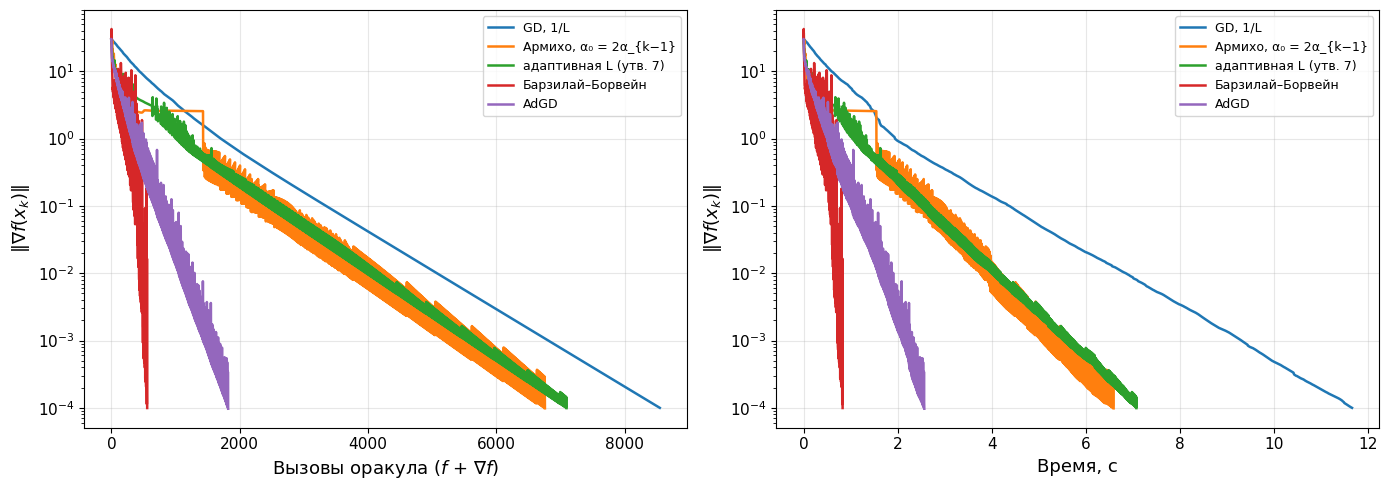

In [11]:
adL = AdaptiveL(L0=1.0)
methods2 = [
    GradientDescent(ConstantStepSize(1 / L),         name="GD, 1/L"),
    GradientDescent(Backtracking(c=1e-4, warm=True),  name="Армихо, α₀ = 2α_{k−1}"),
    GradientDescent(adL,                              name="адаптивная L (утв. 7)"),
    GradientDescent(BB(),                             name="Барзилай–Борвейн"),
    GradientDescent(AdGD(),                           name="AdGD"),
]
for m in methods2:
    m.solve(x0, f, gradf, tol=1e-4, max_iter=60000)
summary(methods2)
k_ad = len(methods2[2].history) - 1; nf_ad = methods2[2].history[-1][2]
print(f"\nутв. 7: пробных вычислений f = {adL.trials} ≤ 2N + log2(2L/L0) = {2 * k_ad + np.log2(2 * L):.0f} "
      f"(всего вызовов f = {nf_ad});  "
      f"max L_k = {max(adL.L_hist):.0f} ≤ 2L = {2 * L:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_methods(methods2, gn, x_axis="calls", ax=axes[0])
plot_methods(methods2, gn, x_axis="time", ax=axes[1])
plt.tight_layout(); plt.show()

### 5.1. Что происходит с оценкой кривизны

Априорная оценка $L\le2 + \lambda\|D\|^2/\sqrt\varepsilon$ отвечает худшему случаю по всем точкам и направлениям. Сравним её с
$\lambda_{\max}(\nabla^2f(x_k))$ и с оценками кривизны, которые строят адаптивные правила.

априорная оценка L        = 1520
λ_max(∇²f) в x0           = 559,  в решении = 1184
медиана L_k у AdGD        = 158.3
медиана L_k адаптивной L  = 512.0


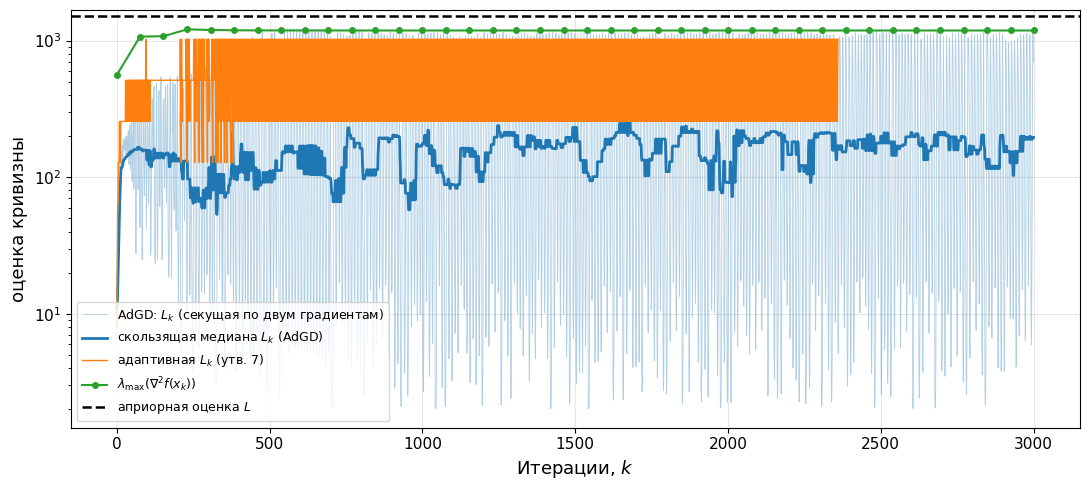

In [12]:
ad = AdGD(); m_ad = GradientDescent(ad, name="AdGD"); m_ad.solve(x0, f, gradf, tol=1e-7, max_iter=60000)
K = len(m_ad.history) - 1
D, lam, eps = P["D"], P["lam"], P["eps"]
def local_L(x):
    d = D @ x
    H = 2 * np.eye(len(x)) + lam * (D.T * (eps / (d * d + eps) ** 1.5)) @ D
    return np.linalg.eigvalsh(H)[-1]
idx = np.unique(np.linspace(0, K, 40).astype(int))
loc = [local_L(m_ad.history[i][0]) for i in idx]
Lk = np.array(ad.L_hist)
med = np.array([np.median(Lk[max(0, i - 50): i + 1]) for i in range(len(Lk))])
print(f"априорная оценка L        = {L:.0f}")
print(f"λ_max(∇²f) в x0           = {loc[0]:.0f},  в решении = {loc[-1]:.0f}")
print(f"медиана L_k у AdGD        = {np.median(Lk):.1f}")
print(f"медиана L_k адаптивной L  = {np.median(adL.L_hist):.1f}")

fig, ax = plt.subplots(figsize=(11, 5))
ax.semilogy(Lk, lw=0.6, alpha=0.35, color="C0", label=r"AdGD: $L_k$ (секущая по двум градиентам)")
ax.semilogy(med, lw=2, color="C0", label=r"скользящая медиана $L_k$ (AdGD)")
ax.semilogy(adL.L_hist, lw=1, color="C1", label=r"адаптивная $L_k$ (утв. 7)")
ax.semilogy(idx, loc, "o-", color="C2", ms=4, lw=1.5, label=r"$\lambda_{\max}(\nabla^2 f(x_k))$")
ax.axhline(L, color="k", ls="--", label=r"априорная оценка $L$")
ax.set_xlabel("Итерации, $k$"); ax.set_ylabel("оценка кривизны"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Локальная кривизна $\lambda_{\max}(\nabla^2 f(x_k))$ меняется вдоль траектории. В начале, где $y$ зашумлён и $|Dx|$ велики, она около $560$,
в решении около $1200$, что в 1.3 раза ниже априорной оценки $1520$. Адаптивная $L$ из утверждения 7 следит за ней
(медиана $512$). У AdGD медиана $L_k\approx150$: он оценивает кривизну вдоль сделанного шага, а вдоль направления движения
она намного меньше максимальной по всем направлениям.

## 6. Невыпуклый пример: овраг Розенброка

$$f(x) = 100(x_2 - x_1^2)^2 + (x_1 - 1)^2,\qquad x^* = (1, 1).$$
Глобальной константы Липшица у градиента нет: вдали от минимума кривизна растёт как $x_1^2$. Постоянный шаг
приходится подбирать по худшему участку траектории, а адаптивные правила подстраиваются под локальную кривизну.

правило                         итераций  вызовов f  вызовов ∇f  время, с
GD, $\alpha=10^{-3}$               32076          0       32076      0.08
Армихо, α₀ = 2α_{k−1}              15628      31265       15628      0.12
Вольф, α₀ = 2α_{k−1}               15628      31265       31256      0.15
адаптивная L                       10670      21351       10670      0.12
AdGD                                8646          0        8646      0.05


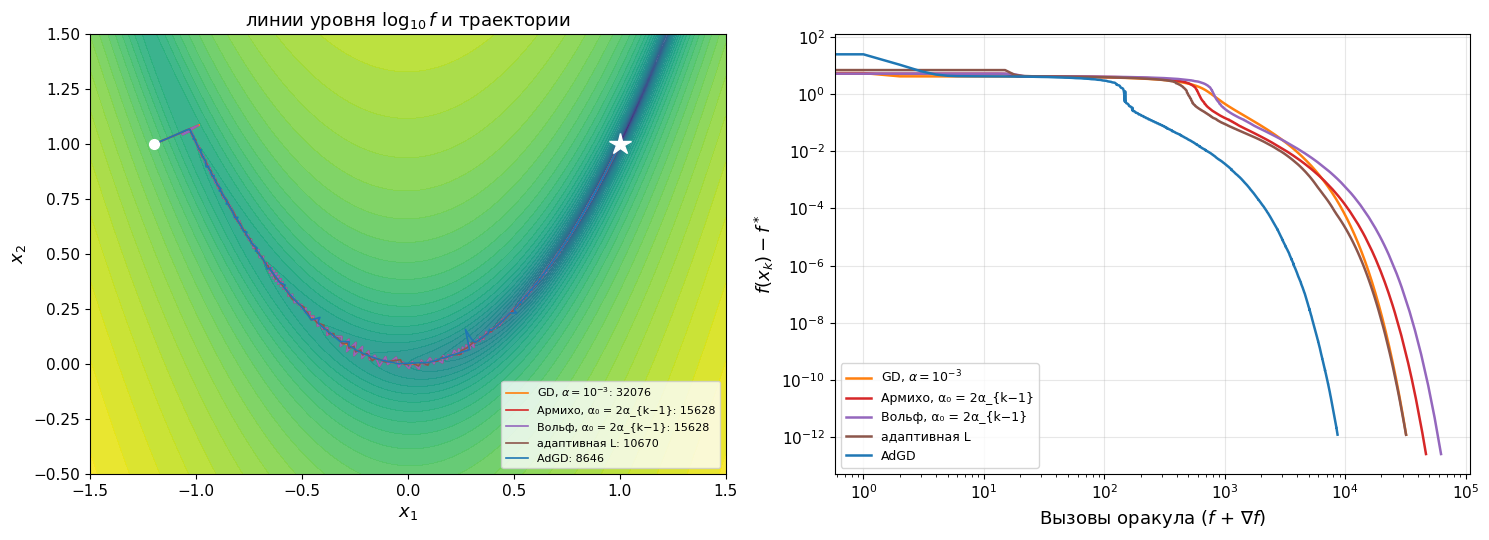

In [13]:
x0r = np.array([-1.2, 1.0])
ms = [GradientDescent(ConstantStepSize(1e-3),        name=r"GD, $\alpha=10^{-3}$"),
      GradientDescent(Backtracking(c=1e-4, warm=True), name="Армихо, α₀ = 2α_{k−1}"),
      GradientDescent(WolfeSearch(warm=True),        name="Вольф, α₀ = 2α_{k−1}"),
      GradientDescent(AdaptiveL(),                   name="адаптивная L"),
      GradientDescent(AdGD(),                        name="AdGD")]
for m in ms:
    m.solve(x0r, rosen, rosen_g, tol=1e-6, max_iter=100000)
summary(ms)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
g1 = np.linspace(-1.5, 1.5, 500); g2 = np.linspace(-0.5, 1.5, 500)
G1, G2 = np.meshgrid(g1, g2); Z = 100 * (G2 - G1**2)**2 + (G1 - 1)**2
axes[0].contourf(G1, G2, np.log10(Z + 1e-3), levels=40, cmap="viridis", alpha=.9)
for m, c in zip(ms, ["C1", "C3", "C4", "C5", "C0"]):
    xy = np.array([r[0] for r in m.history])
    axes[0].plot(xy[:, 0], xy[:, 1], "-", color=c, lw=1.2, label=f"{m.name}: {len(xy)-1}")
axes[0].plot(1, 1, "w*", ms=16); axes[0].plot(*x0r, "wo", ms=7)
axes[0].set_xlabel("$x_1$"); axes[0].set_ylabel("$x_2$"); axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_title(r"линии уровня $\log_{10} f$ и траектории")
for m, c in zip(ms, ["C1", "C3", "C4", "C5", "C0"]):
    axes[1].semilogy([r[2] + r[3] for r in m.history], [rosen(r[0]) + 1e-18 for r in m.history], color=c, label=m.name)
axes[1].set_xlabel(XLABELS["calls"]); axes[1].set_ylabel("$f(x_k) - f^*$"); axes[1].grid(alpha=.3); axes[1].legend(fontsize=9)
axes[1].set_xscale("log")
plt.tight_layout(); plt.show()

Кривизна вдоль траектории меняется на порядки, поэтому постоянный шаг приходится брать по худшему участку. Шаг $10^{-3}$
близок к пределу и требует 32 тысячи итераций. Адаптивные правила быстрее в 2–4 раза: адаптивной $L$ нужно 10.7 тысячи
итераций, AdGD 8.6 тысячи без единого вычисления $f$, Армихо и Вольфу с тёплым стартом 15.6 тысячи.

## Итоги

| правило | что нужно знать | $f$ на итерацию | $\nabla f$ на итерацию | гарантии и замечания |
|---|---|---|---|---|
| $\alpha = 1/L$ | глобальная $L$ | 0 | 1 | утв. 1, плохо, когда $L$ завышена |
| точный поиск | ничего | 0 | $\sim35$ | минимум по лучу, зигзаг не устраняет, дорог |
| Армихо (backtracking) | $\alpha_0, c, \rho$ | $1 + \log_{1/\rho}(\alpha_0L)$ | 1 | утв. 2–3, скорость как у $1/L$ с потерей множителя $\rho$ |
| Армихо, тёплый старт | $c, \rho$ | $\approx2$ | 1 | то же, но дешевле |
| Вольф | $c_1 < c_2$ | несколько | несколько | утв. 4, 6, нужен для квазиньютоновских методов (следующий семестр) |
| Гольдштейн | $c < \tfrac12$ | несколько | 1 | утв. 5, может отрезать минимум $\varphi$ |
| адаптивная $L$ | $L_0$ | $\approx2$ | 1 | утв. 7, $L_k\le2L$ |
| Барзилай–Борвейн | ничего | 0 | 1 | немонотонен, теоретических гарантий нет |
| AdGD | $\lambda_0$ | 0 | 1 | сходимость для выпуклых $f$ без вычисления $f$ |

* Все правила опираются на лемму о спуске (утв. 1): при $\alpha\le1/L$ условие Армихо с $c = \tfrac12$ выполнено
  автоматически, поэтому дробление шага конечно и сохраняет порядок скорости (утв. 2).
* Условие Армихо само по себе разрешает сколь угодно малые шаги. Их запрещает backtracking (старт с большого шага),
  условие кривизны Вольфа или нижняя прямая Гольдштейна.
* Тёплый старт $\alpha_0 = 2\alpha_{k-1}$ уменьшает число вычислений $f$ втрое. Итераций при этом может стать больше: с $\alpha_0 = 1$
  и малым $c$ принимаются более длинные шаги.
* Правила, сравнивающие значения $f$, ограничены по точности: при $\|\nabla f\|\lesssim\sqrt{\epsilon_{\rm mach}|f|/\alpha}$ проверки теряют
  смысл. Правила, использующие только градиенты (BB, AdGD), такого ограничения не имеют.